# Predicción de edad con una CNN
IDA803 · Procesamiento de imágenes · Semana 7

La tarea es estimar una edad en años a partir de una imagen. El ZIP reside en un volumen administrado de Unity Catalog. Para ejecutar el notebook en cómputo serverless usa el entorno base ML v5, que incluye TensorFlow 2.20. En una sesión interactiva puedes seleccionarlo en el panel Environment si tu workspace ofrece esa opción.

Esta copia muestra el código y los resultados de la ejecución original. Para ejecutar el análisis en Databricks, coloca `20-50.zip` en un volumen propio de Unity Catalog e indica su ruta en el parámetro `ruta_volumen`.

## Resultados de la ejecución en Databricks

La prueba usó **6.682 imágenes** después de la auditoría de duplicados y etiquetas en conflicto. La selección se hizo con el MAE de validación.

| Modelo | MAE (años) | RMSE (años) | Dentro de ±5 años |
| --- | ---: | ---: | ---: |
| Mediana de entrenamiento | 7,82 | 9,03 | 34,77 % |
| CNN base | 7,57 | 8,95 | 34,94 % |
| CNN optimizada | 7,46 | 8,79 | 35,12 % |

La CNN optimizada bajó el MAE de prueba un 4,6 % frente a la predicción constante. Los errores son mayores en los extremos del rango de edades. La [gráfica de evaluación](evaluacion.png) y las [métricas completas](metricas.json) se exportaron de esa ejecución.

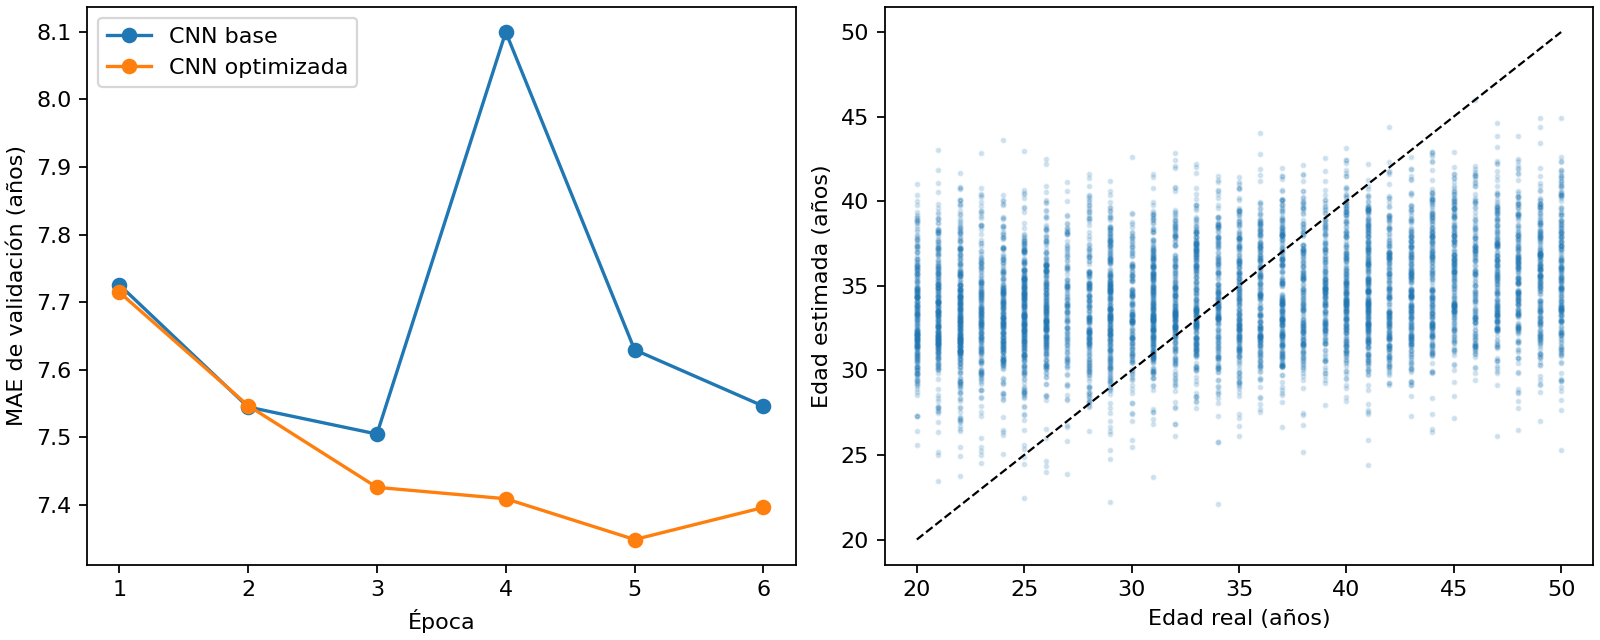

In [ ]:
import hashlib
import io
import json
import os
import re
import shutil
import tempfile
import time
import uuid
from collections import Counter, defaultdict
from pathlib import Path
from zipfile import ZipFile

os.environ.setdefault('TF_NUM_INTRAOP_THREADS', '4')
os.environ.setdefault('TF_NUM_INTEROP_THREADS', '2')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import train_test_split
from tensorflow import keras

SEED = 803
IMAGE_SIZE = (64, 64)
BATCH_SIZE = 128
dbutils.widgets.text('ruta_volumen', '')
volume_path = dbutils.widgets.get('ruta_volumen').strip()
if not volume_path.startswith('/Volumes/'):
    raise ValueError('Indica la ruta de tu volumen de Unity Catalog en ruta_volumen.')
VOLUME = Path(volume_path)
ARCHIVE_PATH = VOLUME / '20-50.zip'

dbutils.widgets.text('epocas', '6')
epochs = int(dbutils.widgets.get('epocas'))
if not 1 <= epochs <= 50:
    raise ValueError('El parámetro epocas debe estar entre 1 y 50.')

keras.utils.set_random_seed(SEED)
run_tag = uuid.uuid4().hex[:12]

## Auditoría y separación de los datos
Cada etiqueta se obtiene del nombre de la carpeta. Se comparan hashes SHA-256 del contenido de los JPEG. Si una imagen exacta tiene etiquetas distintas se excluye por ambigüedad. Para las coincidencias entre conjuntos se conserva la copia de prueba, y dentro de cada conjunto se conserva una copia. Del conjunto de entrenamiento limpio se reserva un 15 % para validación, estratificado por edad. La auditoría de hashes cubre imágenes idénticas; el ZIP no incluye identificadores de personas para verificar coincidencias de identidad.

In [ ]:
def audit_archive(archive):
    by_digest = defaultdict(list)
    original_counts = Counter()
    for entry in sorted(archive.infolist(), key=lambda item: item.filename):
        if entry.is_dir():
            continue
        match = re.fullmatch(r'20-50/(train|test)/(\d+)/[^/]+\.jpg', entry.filename)
        if not match:
            raise ValueError(f'Ruta de imagen inesperada: {entry.filename}')
        split, age = match[1], int(match[2])
        if not 20 <= age <= 50:
            raise ValueError(f'Etiqueta fuera del rango: {entry.filename}')
        digest = hashlib.sha256(archive.read(entry)).digest()
        original_counts[split] += 1
        by_digest[digest].append((split, age, entry))

    kept = {'train': [], 'test': []}
    shared_hashes = 0
    conflicting_hashes = 0
    for group in by_digest.values():
        shared_hashes += int(len({split for split, _, _ in group}) > 1)
        if len({age for _, age, _ in group}) > 1:
            conflicting_hashes += 1
            continue
        split, age, entry = min(group, key=lambda item: (item[0] != 'test', item[2].filename))
        kept[split].append((age, entry))

    return kept, {
        'original': dict(original_counts),
        'unique_clean': {split: len(items) for split, items in kept.items()},
        'hashes_in_both_splits': shared_hashes,
        'hashes_with_conflicting_labels': conflicting_hashes,
    }


def decode_images(archive, entries):
    images = np.empty((len(entries), *IMAGE_SIZE, 3), dtype=np.uint8)
    ages = np.empty(len(entries), dtype=np.float32)
    for index, (age, entry) in enumerate(entries):
        with Image.open(io.BytesIO(archive.read(entry))) as image:
            images[index] = np.asarray(image.convert('RGB').resize(IMAGE_SIZE, Image.Resampling.BILINEAR))
        ages[index] = age
    return images, ages


# Una copia temporal evita lecturas aleatorias contra el almacenamiento remoto del volumen.
with tempfile.TemporaryDirectory() as tmp:
    archive_copy = Path(tmp) / ARCHIVE_PATH.name
    shutil.copyfile(ARCHIVE_PATH, archive_copy)
    with ZipFile(archive_copy) as archive:
        kept, audit = audit_archive(archive)
        train_images, train_ages = decode_images(archive, kept['train'])
        test_images, test_ages = decode_images(archive, kept['test'])

train_indices, validation_indices = train_test_split(
    np.arange(len(train_ages)), test_size=0.15, stratify=train_ages, random_state=SEED
)
audit['used'] = {
    'train': len(train_indices), 'validation': len(validation_indices), 'test': len(test_ages)
}
print(json.dumps(audit, indent=2))

## Arquitectura y entrenamiento
Se usa una CNN compacta con convolución inicial de paso 2, bloques separables con normalización por lotes, agrupación espacial y una salida escalar en años. Las convoluciones separables reducen el costo por capa y el agrupamiento global evita una capa densa sobre todo el mapa espacial. Adam minimiza la pérdida Huber, que atenúa la influencia de errores grandes. Se comparan la mediana de entrenamiento, una CNN base y una variante con aumento, dropout y reducción de la tasa de aprendizaje. Ambas CNN comparten datos, semilla, arquitectura base y máximo de épocas. Se restaura la mejor época por MAE de validación y se elige el modelo con ese mismo criterio.

In [ ]:
def make_dataset(images, ages, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices((images, ages))
    if shuffle:
        dataset = dataset.shuffle(4096, seed=SEED)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 4
    return dataset.batch(BATCH_SIZE).prefetch(1).with_options(options)


def build_model(optimized, initial_age):
    layers = keras.layers
    inputs = keras.Input(shape=(*IMAGE_SIZE, 3), dtype='uint8')
    features = layers.Rescaling(1.0 / 255)(inputs)
    if optimized:
        features = layers.RandomFlip('horizontal', seed=SEED)(features)
        features = layers.RandomRotation(0.035, seed=SEED)(features)
    features = layers.Conv2D(16, 5, strides=2, padding='same', use_bias=False)(features)
    features = layers.BatchNormalization()(features)
    features = layers.Activation('relu')(features)
    for channels in (24, 48, 72):
        features = layers.SeparableConv2D(channels, 3, strides=2, padding='same', use_bias=False)(features)
        features = layers.BatchNormalization()(features)
        features = layers.Activation('relu')(features)
    features = layers.GlobalAveragePooling2D()(features)
    features = layers.Dense(48, activation='relu')(features)
    if optimized:
        features = layers.Dropout(0.15, seed=SEED)(features)
    outputs = layers.Dense(1, bias_initializer=keras.initializers.Constant(initial_age))(features)
    model = keras.Model(inputs, outputs, name='cnn_optimizada' if optimized else 'cnn_base')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.002),
        loss=keras.losses.Huber(delta=3.0),
        metrics=[keras.metrics.MeanAbsoluteError(name='mae')],
    )
    return model


training = make_dataset(train_images[train_indices], train_ages[train_indices], shuffle=True)
validation = make_dataset(train_images[validation_indices], train_ages[validation_indices])
testing = make_dataset(test_images, test_ages)
median_age = float(np.median(train_ages[train_indices]))
del train_images, test_images

models = {}
histories = {}
training_seconds = {}
for name, optimized in [('CNN base', False), ('CNN optimizada', True)]:
    keras.utils.set_random_seed(SEED)
    model = build_model(optimized, median_age)
    callbacks = [keras.callbacks.EarlyStopping(monitor='val_mae', patience=3, restore_best_weights=True)]
    if optimized:
        callbacks.insert(0, keras.callbacks.ReduceLROnPlateau(monitor='val_mae', factor=0.5, patience=1))
    started = time.perf_counter()
    history = model.fit(training, validation_data=validation, epochs=epochs, callbacks=callbacks, verbose=2)
    training_seconds[name] = round(time.perf_counter() - started, 3)
    models[name] = model
    histories[name] = {key: [float(value) for value in values] for key, values in history.history.items()}

validation_mae = {name: min(history['val_mae']) for name, history in histories.items()}
selected = min(validation_mae, key=validation_mae.get)

## Evaluación en prueba y exportación
MAE y RMSE se miden en años. RMSE da más peso a los errores grandes. El sesgo es la media de la predicción menos la edad real. Se informa además el porcentaje de predicciones dentro de cinco años y el error por franja de edad. La evaluación y la API usan la salida escalar sin redondear. Cada ejecución guarda resultados en un directorio separado.

In [ ]:
def describe_errors(actual, predictions):
    error = predictions - actual
    return {
        'mae_years': float(np.mean(np.abs(error))),
        'rmse_years': float(np.sqrt(np.mean(np.square(error)))),
        'bias_years': float(np.mean(error)),
        'within_5_years_pct': float(100 * np.mean(np.abs(error) <= 5)),
    }


predictions = {'Mediana de entrenamiento': np.full_like(test_ages, median_age)}
predictions.update({name: model.predict(testing, verbose=0).ravel() for name, model in models.items()})
test_metrics = {name: describe_errors(test_ages, values) for name, values in predictions.items()}
age_groups = {}
for lower, upper in ((20, 29), (30, 39), (40, 50)):
    mask = (test_ages >= lower) & (test_ages <= upper)
    age_groups[f'{lower}-{upper}'] = {
        'n': int(mask.sum()), **describe_errors(test_ages[mask], predictions[selected][mask])
    }

output_dir = VOLUME / 'resultados' / run_tag
output_dir.mkdir(parents=True, exist_ok=False)
results = {
    'run_tag': run_tag,
    'tensorflow': tf.__version__,
    'seed': SEED,
    'image_size': list(IMAGE_SIZE),
    'epochs_max': epochs,
    'batch_size': BATCH_SIZE,
    'audit': audit,
    'selected_by_validation_mae': selected,
    'median_years': median_age,
    'validation_mae_years': validation_mae,
    'test': test_metrics,
    'selected_test_by_age': age_groups,
    'model_parameters': {name: model.count_params() for name, model in models.items()},
    'training_seconds': training_seconds,
    'history': histories,
    'results_path': str(output_dir),
}

with tempfile.TemporaryDirectory() as tmp:
    model_path = Path(tmp) / 'modelo_edad.keras'
    models[selected].save(model_path)
    shutil.copyfile(model_path, output_dir / model_path.name)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
    for name, history in histories.items():
        epochs_observed = range(1, len(history['val_mae']) + 1)
        axes[0].plot(epochs_observed, history['val_mae'], marker='o', label=name)
    axes[0].set(xlabel='Época', ylabel='MAE de validación (años)')
    axes[0].legend()
    axes[1].scatter(test_ages, predictions[selected], s=3, alpha=0.14)
    axes[1].plot([20, 50], [20, 50], linestyle='--', color='black', linewidth=1)
    axes[1].set(xlabel='Edad real (años)', ylabel='Edad estimada (años)')
    chart_path = Path(tmp) / 'evaluacion.png'
    fig.savefig(chart_path, dpi=160)
    shutil.copyfile(chart_path, output_dir / chart_path.name)
    plt.show()
    plt.close(fig)

(output_dir / 'metricas.json').write_text(json.dumps(results, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.DataFrame.from_dict(test_metrics, orient='index').rename_axis('Modelo').reset_index())
display(pd.DataFrame.from_dict(age_groups, orient='index').rename_axis('Edad real').reset_index())
print(json.dumps(results, ensure_ascii=False, indent=2))
dbutils.notebook.exit(json.dumps(results, ensure_ascii=False))